# 06 · Prometni tok in povezani dejavniki
### Luzern · UTD19 · 2015

**Raziskovalno vprašanje:** Kako so koledar in vremenske razmere povezani z dnevnim prometnim tokom ter kako na te primerjave vpliva pokritost meritev?

Analiza uporablja **79 detektorjev**, izbranih iz učnega obdobja po enakih pravilih kot v zvezku 04. Zemljevid in pregled pokritosti prikazujeta isti nabor.
Rezultati so opisni: povezanost ni dokaz vzročnosti ali učinkovitosti prometnega krmiljenja.

**Vsebina:** [1. Podatki](#podatki) · [2. Priprava](#priprava) · [3. Detektorji](#detektorji) · [4. Koledar](#koledar) · [5. Vreme](#vreme) · [6. Zanesljivost](#zanesljivost) · [7. Sklep](#sklep)


<a id="podatki"></a>
## 1. Podatki in osnovne kontrole

Uporabimo prometne meritve, urne vremenske podatke, koledar in metapodatke detektorjev.
Datoteke naj bodo v korenski mapi projekta oziroma `/content` v Google Colabu. Za zemljevid potrebujemo tudi `detectors_public.csv`.
**OpenStreetMap ne zahteva API ključa**; za nalaganje kartografskih ploščic je potrebna internetna povezava.


In [1]:
from pathlib import Path
from html import escape
import os

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")


In [2]:
# Works from the project root, notebooks/, or Google Colab /content.
required_files = ["luzern_raw.parquet", "luzern_weather_2015.csv", "luzern_calendar_2015.csv"]
configured_data_dir = os.environ.get("TRAFFIC_TWIN_DATA_DIR")
if configured_data_dir:
    DATA_DIR = Path(configured_data_dir).expanduser().resolve()
else:
    candidates = [Path.cwd(), Path.cwd().parent, Path("/content"), Path.home() / "Datasets"]
    DATA_DIR = next((p for p in candidates if all((p / f).is_file() for f in required_files)), None)
if DATA_DIR is None or not all((DATA_DIR / f).is_file() for f in required_files):
    raise FileNotFoundError("Set TRAFFIC_TWIN_DATA_DIR to the directory containing the three Luzern data files.")

OUTPUT_DIR = Path(os.environ.get("TRAFFIC_TWIN_OUTPUT_DIR", str(DATA_DIR / "outputs" / "06_traffic_influence")))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRAFFIC_PATH = DATA_DIR / "luzern_raw.parquet"
WEATHER_PATH = DATA_DIR / "luzern_weather_2015.csv"
CALENDAR_PATH = DATA_DIR / "luzern_calendar_2015.csv"
weather = pd.read_csv(WEATHER_PATH)
calendar = pd.read_csv(CALENDAR_PATH)
con = duckdb.connect()


In [3]:
weather["time_local"] = pd.to_datetime(weather["time_local"])
calendar["date"] = pd.to_datetime(calendar["date"])
assert not weather["time_local"].duplicated().any(), "Duplicate weather timestamps."
assert not calendar["date"].duplicated().any(), "Duplicate calendar dates."
assert weather["time_local"].dt.year.eq(2015).all()
assert calendar["date"].dt.year.eq(2015).all()

traffic_quality = con.execute("""
    SELECT COUNT(*) AS records, COUNT(DISTINCT detid) AS detectors,
           MIN(day) AS first_date, MAX(day) AS last_date,
           COUNT(*) FILTER (WHERE error IS NOT NULL) AS flagged_records,
           COUNT(*) FILTER (WHERE flow IS NULL OR occ IS NULL) AS missing_flow_or_occ
    FROM read_parquet(?)
""", [str(TRAFFIC_PATH)]).df()
traffic_quality["flagged_pct"] = (100 * traffic_quality.flagged_records / traffic_quality.records).round(2)
display(traffic_quality)
display(pd.DataFrame({
    "dataset": ["Weather", "Calendar"],
    "records": [len(weather), len(calendar)],
    "missing_cells": [int(weather.isna().sum().sum()), int(calendar.isna().sum().sum())]
}))


,records,detectors,first_date,last_date,flagged_records,missing_flow_or_occ,flagged_pct
0,26878297,158,2015-01-01,2015-12-31,9065941,0,33.73


,dataset,records,missing_cells
0,Weather,8760,0
1,Calendar,365,0


Prometna zbirka vsebuje 26.878.297 zapisov s 158 detektorjev; 33,73 % zapisov ima oznako napake.
Za analizo ohranimo neoznačene meritve z veljavnim tokom, zasedenostjo in časovnim intervalom.
Pomen kode `error=1` še ni potrjen iz dokumentacije, zato je izločanje previdnostna izbira.

Analizo izvedemo **na dnevni ravni**. Prometni intervali segajo od 180 do 86400 sekund; 24:00 pripišemo poročevalskemu dnevu `day`.
Dnevno združevanje ne razreši negotovosti glede časovnega pasu, DST ali pomena mejnih intervalov; pred urno analizo je to treba preveriti.


<a id="priprava"></a>
## 2. Izbor detektorjev in priprava dnevnih podatkov

Izbor uporablja samo podatke **pred 13. 9. 2015**: detektor mora imeti vsaj 175 dni z najmanj 400 veljavnimi triminutnimi intervali.
Za dnevne primerjave nato ohranimo samo detektor–dan z vsaj 400 intervali od pričakovanih 480.


In [4]:
TRAIN_END = pd.Timestamp("2015-09-13")

detector_quality = con.execute("""
    WITH daily_quality AS (
        SELECT
            detid,
            day,
            COUNT(DISTINCT interval) AS valid_intervals
        FROM read_parquet(?)
        WHERE day < ?
          AND error IS NULL
          AND flow IS NOT NULL
          AND occ BETWEEN 0 AND 1
          AND flow BETWEEN 0 AND 99998
          AND interval BETWEEN 0 AND 86400
          AND interval % 180 = 0
        GROUP BY detid, day
    )
    SELECT
        detid,
        COUNT(*) FILTER (
            WHERE valid_intervals >= 400
        ) AS reliable_days,
        SUM(valid_intervals) AS valid_observations
    FROM daily_quality
    GROUP BY detid
    HAVING COUNT(*) FILTER (
        WHERE valid_intervals >= 400
    ) >= 175
    ORDER BY reliable_days DESC, valid_observations DESC
""", [str(TRAFFIC_PATH), TRAIN_END.date()]).df()

selected_detectors = detector_quality["detid"].tolist()

print("Selected detectors:", len(selected_detectors))
assert len(selected_detectors) == 79, "Selection changed: review the scope and conclusions."


Selected detectors: 79


In [5]:
MIN_DAILY_OBSERVATIONS = 400
con.register("selected_detector_ids", detector_quality[["detid"]])

# Daily means must not give duplicate measurements extra weight.
duplicate_valid_groups = con.execute("""
    SELECT COUNT(*) FROM (
        SELECT t.detid, t.day, t.interval
        FROM read_parquet(?) AS t
        INNER JOIN selected_detector_ids AS s ON t.detid = s.detid
        WHERE t.error IS NULL AND t.flow BETWEEN 0 AND 99998
          AND t.occ BETWEEN 0 AND 1
          AND t.interval BETWEEN 180 AND 86400 AND t.interval % 180 = 0
        GROUP BY t.detid, t.day, t.interval HAVING COUNT(*) > 1
    )
""", [str(TRAFFIC_PATH)]).fetchone()[0]
assert duplicate_valid_groups == 0, "Resolve valid duplicate measurements before aggregation."

traffic_daily = con.execute("""
    SELECT CAST(t.day AS DATE) AS date, t.detid,
           AVG(t.flow) AS avg_flow, AVG(t.occ) AS avg_occupancy,
           COUNT(DISTINCT t.interval) AS observations
    FROM read_parquet(?) AS t
    INNER JOIN selected_detector_ids AS s ON t.detid = s.detid
    WHERE t.error IS NULL AND t.flow BETWEEN 0 AND 99998
      AND t.occ BETWEEN 0 AND 1
      AND t.interval BETWEEN 180 AND 86400 AND t.interval % 180 = 0
    GROUP BY t.day, t.detid ORDER BY date, t.detid
""", [str(TRAFFIC_PATH)]).df()
traffic_daily["date"] = pd.to_datetime(traffic_daily["date"])
traffic_daily_reliable = traffic_daily.loc[traffic_daily.observations >= MIN_DAILY_OBSERVATIONS].copy()

weather_daily = weather.assign(date=weather.time_local.dt.normalize()).groupby("date", as_index=False).agg(
    avg_temperature_c=("temperature_2m_c", "mean"),
    total_precipitation_mm=("precipitation_mm", "sum"),
    avg_humidity_pct=("relative_humidity_2m_pct", "mean"),
    avg_wind_kmh=("wind_speed_10m_kmh", "mean")
)
traffic_combined = (
    traffic_daily_reliable.merge(weather_daily, on="date", how="left", validate="many_to_one")
    .merge(calendar, on="date", how="left", validate="many_to_one")
)
assert not traffic_combined.isna().any().any(), "Unmatched or missing values after merging."
assert traffic_combined.detid.nunique() == 79

# One observation per day avoids treating shared weather as independent sensor observations.
daily_analysis = traffic_combined.groupby("date", as_index=False).agg(
    avg_flow=("avg_flow", "mean"),
    precipitation_mm=("total_precipitation_mm", "first"),
    temperature_c=("avg_temperature_c", "first"),
    is_weekend=("is_weekend", "first"), is_holiday=("is_holiday", "first"),
    detectors_available=("detid", "nunique")
)
display(pd.DataFrame({
    "selected_detectors": [len(selected_detectors)],
    "all_detector_days": [len(traffic_daily)],
    "reliable_detector_days": [len(traffic_daily_reliable)],
    "analysis_days": [len(daily_analysis)]
}))


,selected_detectors,all_detector_days,reliable_detector_days,analysis_days
0,79,28271,26709,361


Po filtriranju ostane **26.709 zanesljivih zapisov detektor–dan, 79 detektorjev in 361 dni**.
Dnevni kazalnik je povprečje razpoložljivih detektorskih tokov; ni vsota vozil v mestu.
Ker se razpoložljive lokacije in intervali med dnevi razlikujejo, zanesljivost primerjav dodatno preverimo v razdelku 6.


<a id="detektorji"></a>
## 3. Kje je 79 analiziranih detektorjev?

### 3.1 Interaktivni zemljevid OpenStreetMap

Barva označuje delež dni z vsaj 400 veljavnimi intervali glede na **vseh 365 dni** leta 2015.
Detektor poiščemo po `detid`; prehod z miško ali klik prikaže podrobnosti. Sivi detektorji zunaj izbranega nabora so izbirni sloj.


In [6]:
import folium
from folium.plugins import Search, Fullscreen
from branca.colormap import LinearColormap

metadata_path = DATA_DIR / "detectors_public.csv"
if not metadata_path.exists():
    raise FileNotFoundError("For the detector map, place detectors_public.csv in DATA_DIR.")
metadata = pd.read_csv(metadata_path, dtype={"detid": str, "linkid": str}, low_memory=False)
metadata = metadata.loc[metadata["citycode"].str.lower().eq("luzern")].copy()
metadata["road"] = metadata["road"].fillna("Road not specified")
assert not metadata["detid"].duplicated().any(), "Ambiguous metadata: duplicate Luzern detector IDs."
for name in ["lat", "long"]:
    metadata[name] = pd.to_numeric(metadata[name], errors="coerce")

detector_year = traffic_daily_reliable.groupby("detid", as_index=False).agg(
    reliable_days_2015=("date", "nunique"), mean_flow_2015=("avg_flow", "mean")
)
detector_map_data = (
    detector_quality.rename(columns={"reliable_days": "reliable_days_train"})
    .merge(detector_year, on="detid", how="left", validate="one_to_one")
    .merge(metadata, on="detid", how="left", validate="one_to_one", indicator=True)
    .sort_values(["road", "detid"]).reset_index(drop=True)
)
assert len(selected_detectors) == 79, "The input selection changed; review the map title and conclusions."
assert len(detector_map_data) == 79 and set(detector_map_data.detid) == set(selected_detectors)
missing_locations = detector_map_data.loc[
    detector_map_data["_merge"].ne("both")
    | ~detector_map_data["lat"].between(-90, 90)
    | ~detector_map_data["long"].between(-180, 180), "detid"
].tolist()
assert not missing_locations, f"Missing or invalid detector coordinates: {missing_locations}"
detector_map_data = detector_map_data.drop(columns="_merge")
detector_map_data["reliable_days_pct"] = 100 * detector_map_data["reliable_days_2015"] / 365
detector_map_data["map_number"] = np.arange(1, len(detector_map_data) + 1)
detector_map_data.to_csv(OUTPUT_DIR / "selected_79_detectors.csv", index=False)

observed_ids = con.execute("SELECT DISTINCT detid FROM read_parquet(?)", [str(TRAFFIC_PATH)]).df()
other_detectors = metadata.loc[
    metadata.detid.isin(observed_ids.detid) & ~metadata.detid.isin(selected_detectors)
].dropna(subset=["lat", "long"])

coverage_colors = LinearColormap(
    ["#f59e0b", "#22b8a5", "#124b82"], vmin=0, vmax=100,
    caption="Reliable detector-days / 365 days (%)"
)
detector_map = folium.Map(
    location=[detector_map_data.lat.mean(), detector_map_data.long.mean()],
    tiles="OpenStreetMap", zoom_start=13, control_scale=True, height=680
)
Fullscreen().add_to(detector_map)
context_layer = folium.FeatureGroup(name=f"Other observed detectors ({len(other_detectors)})", show=False)
for row in other_detectors.itertuples():
    folium.CircleMarker(
        [row.lat, row.long], radius=3, color="#94a3b8", weight=1,
        fill=True, fill_opacity=0.45, tooltip=f"Outside the selected 79: {escape(row.detid)}"
    ).add_to(context_layer)
context_layer.add_to(detector_map)

features = []
for row in detector_map_data.itertuples():
    properties = {
        "detid": row.detid, "road": str(row.road), "linkid": str(row.linkid),
        "reliable_days_train": int(row.reliable_days_train),
        "reliable_days_2015": int(row.reliable_days_2015),
        "reliable_days_pct": round(row.reliable_days_pct, 1),
        "mean_flow_2015": round(row.mean_flow_2015, 1)
    }
    features.append({"type":"Feature", "geometry":{"type":"Point", "coordinates":[row.long, row.lat]},
                     "properties":properties})
selected_layer = folium.GeoJson(
    {"type":"FeatureCollection", "features":features}, name="Selected 79 detectors",
    marker=folium.CircleMarker(radius=6, fill=True, fill_opacity=0.95),
    style_function=lambda f: {"color":"#ffffff", "weight":1.3,
                              "fillColor":coverage_colors(f["properties"]["reliable_days_pct"])},
    tooltip=folium.GeoJsonTooltip(
        fields=["detid", "road", "reliable_days_2015", "reliable_days_pct"],
        aliases=["Detector", "Road", "Reliable days / 365", "Reliable days (%)"]
    ),
    popup=folium.GeoJsonPopup(
        fields=["detid", "road", "linkid", "reliable_days_train", "reliable_days_2015", "reliable_days_pct", "mean_flow_2015"],
        aliases=["Detector", "Road", "Link", "Reliable training days", "Reliable days / 365", "Reliable days (%)", "Mean flow on reliable days"],
        max_width=360
    )
).add_to(detector_map)
Search(layer=selected_layer, search_label="detid", placeholder="Search one of 79 detector IDs",
       collapsed=False, position="topleft", search_zoom=18).add_to(detector_map)

coverage_colors.add_to(detector_map)
folium.LayerControl(collapsed=False).add_to(detector_map)
detector_map.fit_bounds([
    [detector_map_data.lat.min(), detector_map_data.long.min()],
    [detector_map_data.lat.max(), detector_map_data.long.max()]
], padding=(35, 35))
detector_map.get_root().html.add_child(folium.Element("""
<div style="position:fixed;bottom:28px;left:16px;z-index:9999;background:white;
padding:13px 17px;border-radius:10px;box-shadow:0 2px 14px #0002;font:14px Arial;max-width:330px">
<b style="font-size:19px;color:#124b82">Luzern · 79 analysed detectors</b><br>
UTD19 · 2015 · 79 selected detectors<br>
<span style="color:#64748b">Colour = days with ≥400 valid intervals / 365.<br>
OpenStreetMap · no API key required. Search by detid.<br>Multiple lanes may share nearly identical coordinates.</span></div>
"""))
detector_map.save(str(OUTPUT_DIR / "selected_79_detectors_map.html"))
print(f"Mapped: {len(features)}/{len(selected_detectors)} selected detectors; missing coordinates: {len(missing_locations)}")
display(detector_map)


Mapped: 79/79 selected detectors; missing coordinates: 0


### 3.2 Časovna pokritost vseh 79 detektorjev

Vsaka vrstica je en detektor, vsak stolpec en dan. Modra pomeni vsaj 400 veljavnih intervalov, oranžna manj kot 400, siva pa odsotnost veljavnih meritev.
Manjkajoče meritve niso ničelni promet. Desno je delež zanesljivih dni v letu.


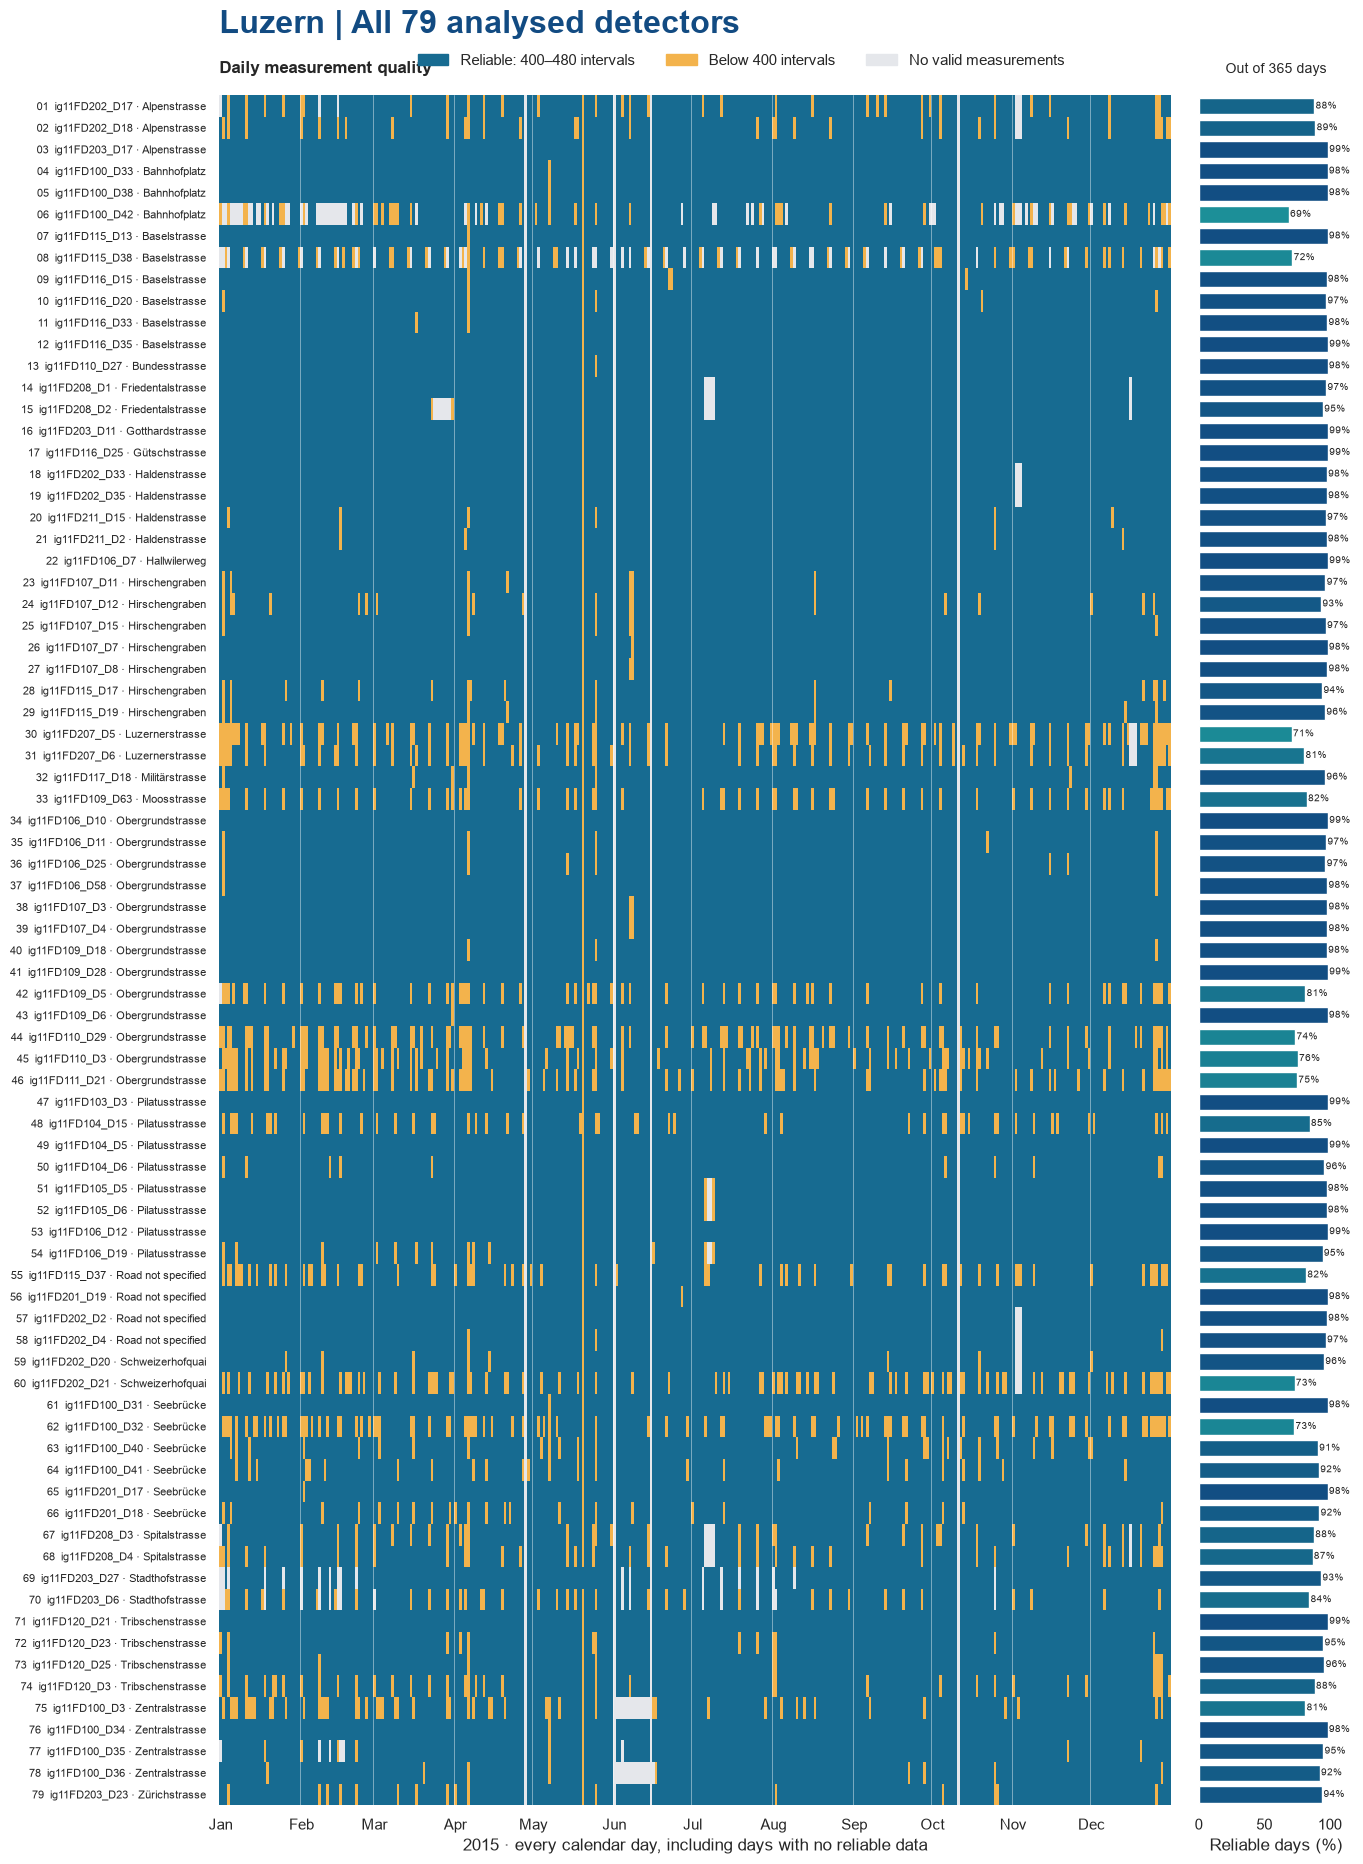

In [7]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

all_dates_2015 = pd.date_range("2015-01-01", "2015-12-31", freq="D")
detector_order = detector_map_data["detid"].tolist()
coverage_matrix = traffic_daily.pivot(index="detid", columns="date", values="observations").reindex(
    index=detector_order, columns=all_dates_2015
)
coverage_states = np.where(coverage_matrix.isna(), 0,
                           np.where(coverage_matrix >= MIN_DAILY_OBSERVATIONS, 2, 1))
assert coverage_states.shape == (79, 365)
assert int((coverage_states == 2).sum()) == len(traffic_daily_reliable)

fig, (ax, bar_ax) = plt.subplots(1, 2, figsize=(18, 19),
    gridspec_kw={"width_ratios":[8, 1.3], "wspace":0.05}, sharey=True)
fig.patch.set_facecolor("white")
ax.imshow(coverage_states, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["#e5e7eb", "#f3b34c", "#176b91"]),
          norm=BoundaryNorm([-0.5,0.5,1.5,2.5], 3))
labels = [f"{r.map_number:02d}  {r.detid} · {r.road}" for r in detector_map_data.itertuples()]
ax.set_yticks(np.arange(79), labels=labels, fontsize=8)
month_starts = pd.date_range("2015-01-01", "2015-12-01", freq="MS")
month_positions = (month_starts - all_dates_2015[0]).days
ax.set_xticks(month_positions, labels=month_starts.strftime("%b"))
ax.set_xlabel("2015 · every calendar day, including days with no reliable data")
ax.set_title("Daily measurement quality", loc="left", fontweight="bold", pad=16)
for pos in month_positions[1:]:
    ax.axvline(pos - 0.5, color="white", alpha=0.5, linewidth=0.6)
percentages = (coverage_states == 2).sum(axis=1) / 365 * 100
bar_ax.barh(np.arange(79), percentages, color=[coverage_colors(x) for x in percentages], height=0.76)
for i, value in enumerate(percentages):
    bar_ax.text(value + 1, i, f"{value:.0f}%", va="center", fontsize=7)
bar_ax.set_xlim(0, 118)
bar_ax.set_xticks([0, 50, 100])
bar_ax.tick_params(axis="y", left=False, labelleft=False)
bar_ax.set_xlabel("Reliable days (%)")
bar_ax.set_title("Out of 365 days", fontsize=10, pad=16)
for a in [ax, bar_ax]:
    a.grid(False)
    for spine in a.spines.values():
        spine.set_visible(False)
fig.suptitle("Luzern | All 79 analysed detectors", x=0.35, y=0.985, ha="left", fontsize=23, fontweight="bold", color="#124b82")
fig.legend(handles=[Patch(color="#176b91",label="Reliable: 400–480 intervals"),
                    Patch(color="#f3b34c",label="Below 400 intervals"),
                    Patch(color="#e5e7eb",label="No valid measurements")],
           loc="upper center", bbox_to_anchor=(0.64,0.969), ncol=3, frameon=False)
fig.subplots_adjust(left=0.35, right=0.98, top=0.94, bottom=0.04)
fig.savefig(OUTPUT_DIR / "selected_79_detectors_coverage.png", dpi=160, bbox_inches="tight", facecolor="white")
plt.show()


<a id="koledar"></a>
## 4. Koledarski vzorci

Praznike obravnavamo pred vikendi: skupine **delovni dan, vikend in praznik** se ne prekrivajo.
Vsak dan šteje enkrat; ob povprečjih navedemo tudi število dni.


<ipython-input-8-ae12656ea553>:15: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  calendar_analysis["date"].dt.dayofweek


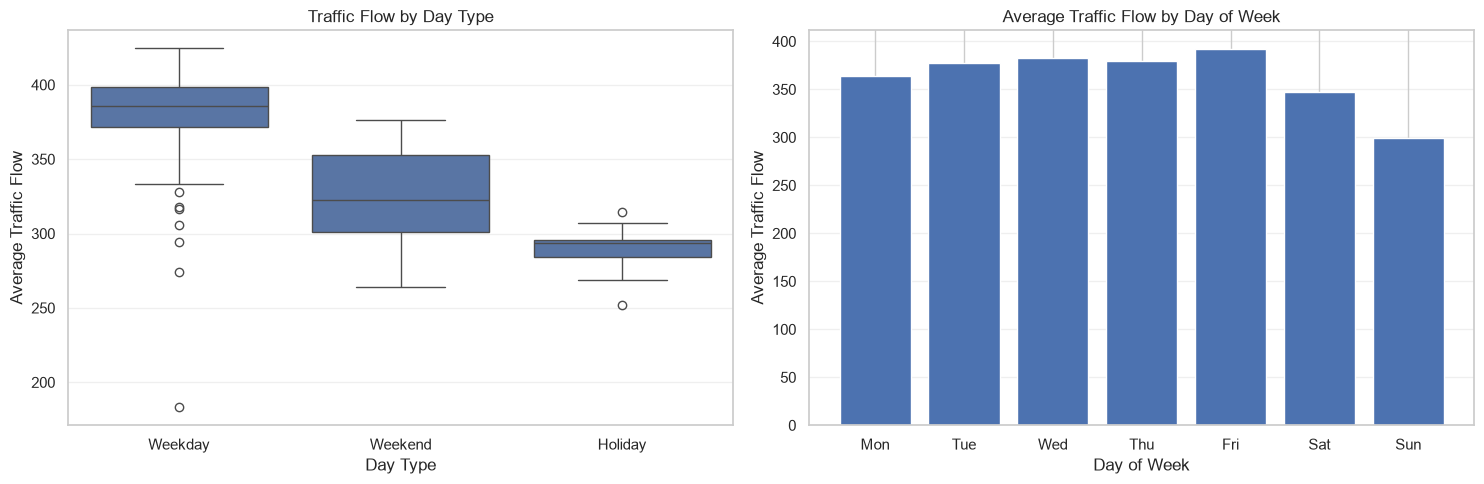

,days,mean_flow,median_flow,std_flow
day_type,,,,
Holiday,13,289.73,293.44,16.01
Weekday,249,382.75,385.74,25.32
Weekend,99,324.72,322.22,29.79


In [8]:
calendar_analysis = daily_analysis.copy()


calendar_analysis["day_type"] = np.select(
    [
        calendar_analysis["is_holiday"] == 1,
        calendar_analysis["is_weekend"] == 1
    ],
    ["Holiday", "Weekend"],
    default="Weekday"
)


calendar_analysis["day_of_week"] = (
    calendar_analysis["date"].dt.dayofweek
)

day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=calendar_analysis,
    x="day_type",
    y="avg_flow",
    order=["Weekday", "Weekend", "Holiday"],
    ax=axes[0]
)

axes[0].set_title("Traffic Flow by Day Type")
axes[0].set_xlabel("Day Type")
axes[0].set_ylabel("Average Traffic Flow")
axes[0].grid(axis="y", alpha=0.3)

weekday_flow = (
    calendar_analysis
    .groupby("day_of_week")["avg_flow"]
    .mean()
    .reindex(range(7))
)

axes[1].bar(day_names, weekday_flow.values)
axes[1].set_title("Average Traffic Flow by Day of Week")
axes[1].set_xlabel("Day of Week")
axes[1].set_ylabel("Average Traffic Flow")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


calendar_summary = (
    calendar_analysis
    .groupby("day_type")
    .agg(
        days=("date", "count"),
        mean_flow=("avg_flow", "mean"),
        median_flow=("avg_flow", "median"),
        std_flow=("avg_flow", "std")
    )
    .round(2)
)

display(calendar_summary)


Povprečni tok znaša **382,75 med delovnimi dnevi, 324,72 med vikendi in 289,73 med prazniki**.
Vikendi so približno 15,2 %, prazniki pa 24,3 % pod delovnimi dnevi. Gre za opisne razlike; prazničnih dni je le 13.


<a id="vreme"></a>
## 5. Povezava z vremenskimi dejavniki

### 5.1 Padavine in temperatura

Primerjamo dnevne vremenske povzetke in dnevni povprečni prometni tok. Korelacije izračunamo na 361 dnevih, ne na posameznih detektorskih zapisih.


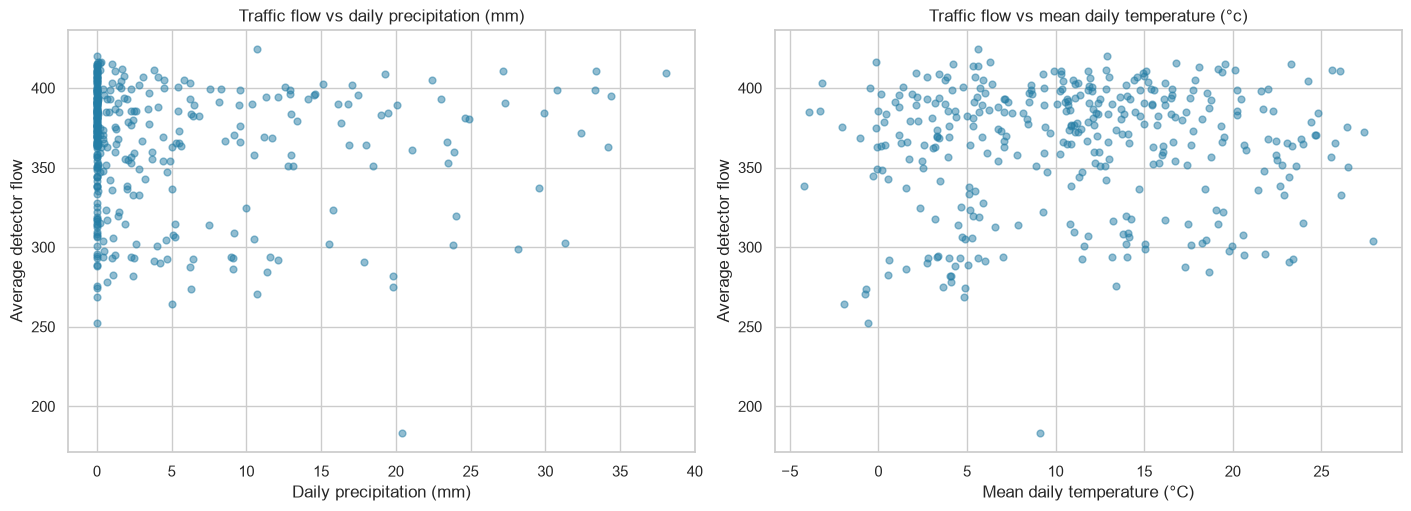

,pearson,spearman
precipitation_mm,-0.0360,-0.0846
temperature_c,0.0622,0.0406


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, feature, label in zip(axes, ["precipitation_mm", "temperature_c"],
                             ["Daily precipitation (mm)", "Mean daily temperature (°C)"]):
    ax.scatter(daily_analysis[feature], daily_analysis.avg_flow, s=24, alpha=0.5, color="#247da5")
    ax.set(xlabel=label, ylabel="Average detector flow", title=f"Traffic flow vs {label.lower()}")
plt.show()
weather_pair_correlations = pd.DataFrame({
    feature: {method: daily_analysis[feature].corr(daily_analysis.avg_flow, method=method)
              for method in ["pearson", "spearman"]}
    for feature in ["precipitation_mm", "temperature_c"]
}).T
display(weather_pair_correlations.round(4))


### 5.2 Skupni pregled vremenskih povezav

Matrika loči povezave s tokom od povezav med samimi vremenskimi spremenljivkami.


Weather factors ranked by absolute Spearman correlation:


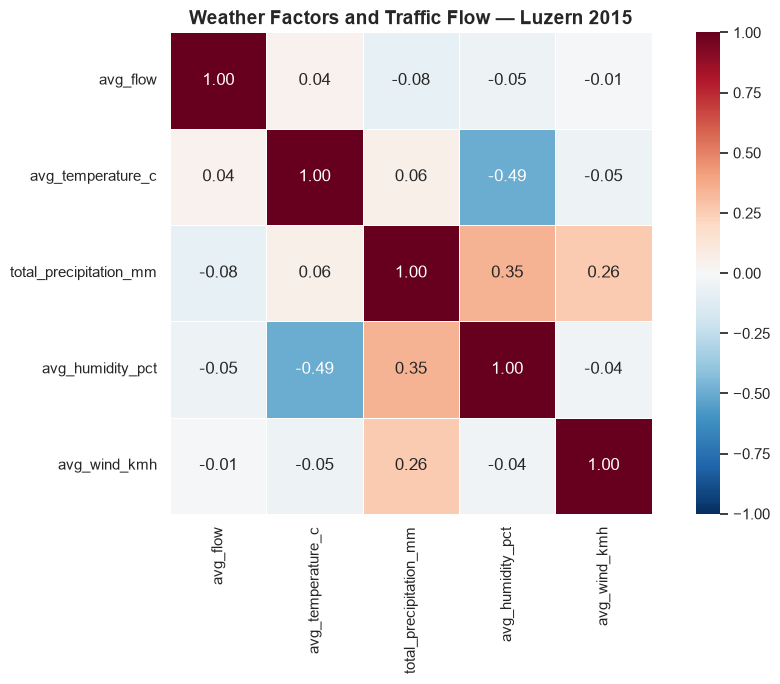

,spearman_correlation
total_precipitation_mm,-0.084569
avg_humidity_pct,-0.051203
avg_temperature_c,0.040641
avg_wind_kmh,-0.007900


In [10]:
weather_features = [
    "avg_temperature_c",
    "total_precipitation_mm",
    "avg_humidity_pct",
    "avg_wind_kmh"
]

# One observation per day
weather_analysis = (
    daily_analysis[["date", "avg_flow"]]
    .merge(
        weather_daily[["date"] + weather_features],
        on="date",
        how="inner",
        validate="one_to_one"
    )
)

# Calculate correlation matrix
correlation_matrix = weather_analysis[
    ["avg_flow"] + weather_features
].corr(method="spearman")

# Visualize correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title(
    "Weather Factors and Traffic Flow — Luzern 2015",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Rank weather factors by correlation with traffic flow
weather_ranking = (
    correlation_matrix["avg_flow"]
    .drop("avg_flow")
    .sort_values(key=abs, ascending=False)
)

print("Weather factors ranked by absolute Spearman correlation:")
display(weather_ranking.to_frame("spearman_correlation"))


### 5.3 Preverba po upoštevanju koledarja in pokritosti

Neprilagojene dnevne povezave so šibke (največji |Spearman ρ| je približno **0,085**).
Za opisno preverbo iz toka in vremenske spremenljivke odstranimo linearno napovedljiv del glede na **mesec, vrsto dneva in število dostopnih detektorjev**.
Pearsonova korelacija ostankov ni ocena vzročnega učinka ali statistične značilnosti.


In [11]:
adjusted_weather_data = weather_analysis.merge(
    calendar_analysis[["date", "day_type", "detectors_available"]],
    on="date", validate="one_to_one"
).sort_values("date")
controls = pd.get_dummies(
    pd.DataFrame({"month": adjusted_weather_data.date.dt.month.astype(str),
                  "day_type": adjusted_weather_data.day_type}),
    drop_first=True, dtype=float
)
controls["detectors_available"] = adjusted_weather_data["detectors_available"].to_numpy()
X_controls = np.column_stack([np.ones(len(controls)), controls.to_numpy(dtype=float)])
def residualize(values):
    values = np.asarray(values, dtype=float)
    return values - X_controls @ np.linalg.lstsq(X_controls, values, rcond=None)[0]

flow_residuals = residualize(adjusted_weather_data["avg_flow"])
adjusted_weather_summary = pd.DataFrame([
    {"weather_feature": feature,
     "raw_pearson": adjusted_weather_data[feature].corr(adjusted_weather_data["avg_flow"]),
     "adjusted_pearson": pd.Series(residualize(adjusted_weather_data[feature])).corr(pd.Series(flow_residuals)),
     "days": len(adjusted_weather_data)}
    for feature in weather_features
]).set_index("weather_feature")
display(adjusted_weather_summary.round(4))
adjusted_weather_summary.to_csv(OUTPUT_DIR / "weather_adjusted_associations.csv")
print("These are descriptive associations. No confidence intervals or causal effects are estimated.")


These are descriptive associations. No confidence intervals or causal effects are estimated.


,raw_pearson,adjusted_pearson,days
weather_feature,,,
avg_temperature_c,0.0622,-0.0224,361
total_precipitation_mm,-0.0360,-0.0035,361
avg_humidity_pct,-0.0828,-0.0191,361
avg_wind_kmh,0.0024,0.0717,361


### 5.4 Padavine po vrsti dneva

Preverimo, ali skupna povprečja prikrijejo razlike med vrstami dni. Celice z manj kot tremi dnevi skrijemo.
Prikaz vsebuje povprečje in število dni, da majhnih skupin ne precenimo.


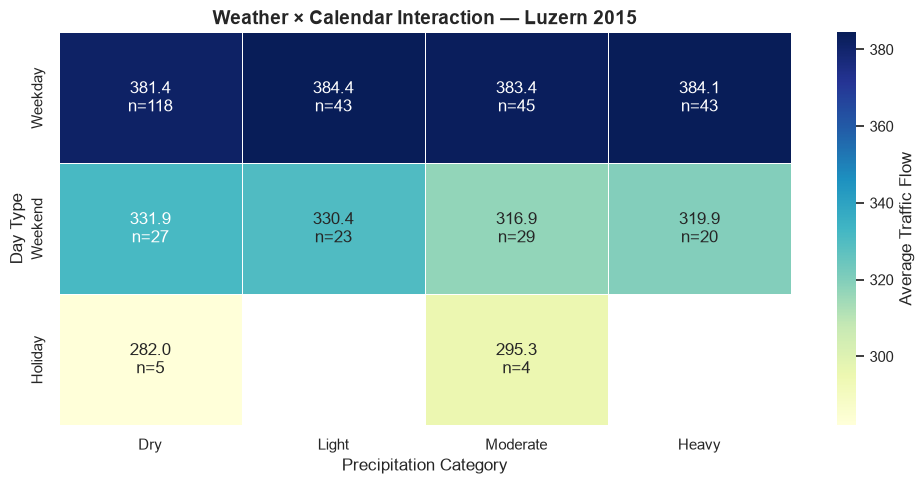

In [12]:
interaction_data = calendar_analysis.copy()

interaction_data["rain_category"] = pd.cut(
    interaction_data["precipitation_mm"].round(6),  # Keep category boundaries stable against floating-point noise.
    bins=[-0.001, 0, 2, 10, np.inf],
    labels=["Dry", "Light", "Moderate", "Heavy"]
)


interaction_summary = (
    interaction_data
    .groupby(["day_type", "rain_category"], observed=True)
    .agg(
        days=("avg_flow", "count"),
        mean_flow=("avg_flow", "mean")
    )
    .reset_index()
)


interaction_summary.loc[
    interaction_summary["days"] < 3, "mean_flow"
] = np.nan

interaction_matrix = interaction_summary.pivot(
    index="day_type",
    columns="rain_category",
    values="mean_flow"
)

interaction_matrix = interaction_matrix.reindex(
    ["Weekday", "Weekend", "Holiday"]
)

interaction_counts = interaction_summary.pivot(index="day_type", columns="rain_category", values="days").reindex(index=interaction_matrix.index, columns=interaction_matrix.columns)
interaction_annotations = interaction_matrix.copy().astype(object)
for i in range(interaction_matrix.shape[0]):
    for j in range(interaction_matrix.shape[1]):
        value = interaction_matrix.iloc[i, j]
        count = interaction_counts.iloc[i, j]
        interaction_annotations.iloc[i, j] = "" if pd.isna(value) else f"{value:.1f}\nn={int(count)}"

plt.figure(figsize=(10, 5))

sns.heatmap(
    interaction_matrix,
    annot=interaction_annotations,
    fmt="",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Average Traffic Flow"}
)

plt.title(
    "Weather × Calendar Interaction — Luzern 2015",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Precipitation Category")
plt.ylabel("Day Type")

plt.grid(False)
plt.tight_layout()
plt.show()


Med delovnimi dnevi so povprečja po padavinskih kategorijah podobna; pri vikendih so razlike večje.
Šibka dnevna povezanost **ne izključuje urnih, lokalnih ali nelinearnih učinkov**. Uporabnost vremena za napovedovanje je treba preveriti s primerjavo modelov.


<a id="zanesljivost"></a>
## 6. Kako pokritost vpliva na zaključke?

### 6.1 Razpoložljivost detektorjev

Razpoložljivost obravnavamo neposredno kot število detektorjev in preverimo njeno povezanost s tokom.


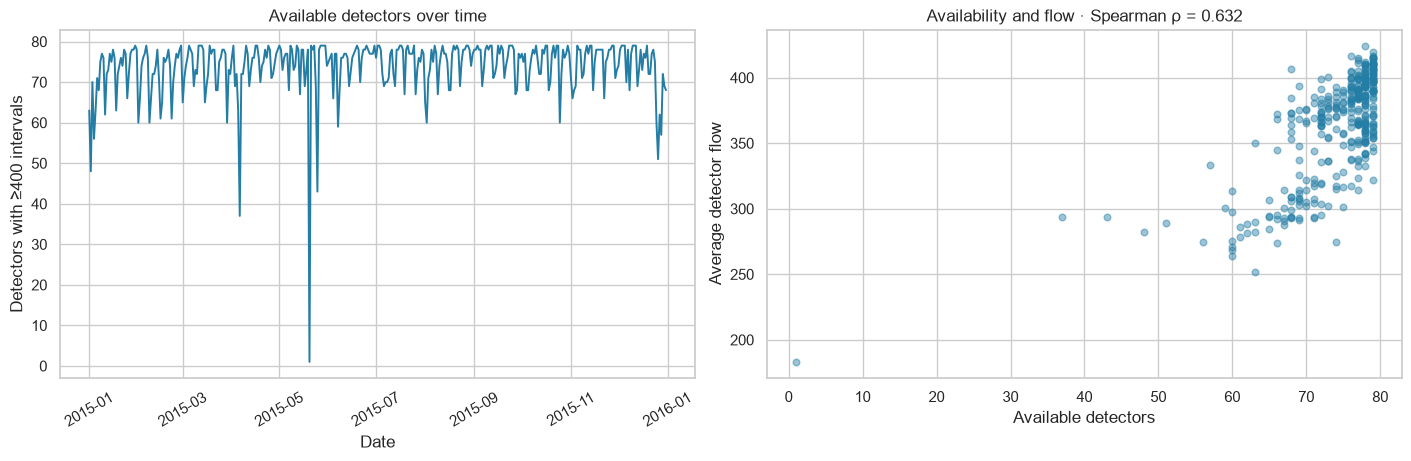

In [13]:
coverage_data = daily_analysis.sort_values("date")
coverage_corr = coverage_data.detectors_available.corr(coverage_data.avg_flow, method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
axes[0].plot(coverage_data.date, coverage_data.detectors_available, color="#247da5", linewidth=1.4)
axes[0].set(title="Available detectors over time", xlabel="Date", ylabel="Detectors with ≥400 intervals")
axes[0].tick_params(axis="x", rotation=30)
axes[1].scatter(coverage_data.detectors_available, coverage_data.avg_flow, s=23, alpha=0.45, color="#247da5")
axes[1].set(title=f"Availability and flow · Spearman ρ = {coverage_corr:.3f}",
            xlabel="Available detectors", ylabel="Average detector flow")
plt.show()


### 6.2 Enak nabor detektorjev in enaki dnevi

Primerjamo tri načine izračuna:

1. **Glavna analiza:** vseh 79 izbranih detektorjev, vendar vsak dan le razpoložljivi.
2. **Podnabor 71:** enaka utež vsakega detektorja; vsaj 100 delovnih, 40 vikend in 5 prazničnih dni na detektor. Razpoložljivi datumi se še razlikujejo.
3. **Strogi panel 79:** samo dnevi, ko ima vsak od vseh 79 detektorjev vsaj 400 intervalov. Datumi in lokacije so skupni; ure meritev znotraj dneva se še lahko razlikujejo.


In [14]:
fixed_data = traffic_daily_reliable.copy()
fixed_data["date"] = pd.to_datetime(fixed_data["date"])


fixed_data = fixed_data.merge(
    calendar[["date", "is_weekend", "is_holiday"]].assign(
        date=lambda df: pd.to_datetime(df["date"])
    ),
    on="date",
    how="inner"
)

# Classify days
fixed_data["day_type"] = np.select(
    [
        fixed_data["is_holiday"] == 1,
        fixed_data["is_weekend"] == 1
    ],
    ["Holiday", "Weekend"],
    default="Weekday"
)

# Count observations per detector and day type
detector_counts = (
    fixed_data.groupby(["detid", "day_type"])["date"]
    .nunique()
    .unstack(fill_value=0)
)

# Require sufficient observations in all categories
eligible_detectors = detector_counts[
    (detector_counts["Weekday"] >= 100) &
    (detector_counts["Weekend"] >= 40) &
    (detector_counts["Holiday"] >= 5)
].index

fixed_data = fixed_data[
    fixed_data["detid"].isin(eligible_detectors)
].copy()

print("Eligible detectors:", len(eligible_detectors))

# Mean flow for each detector and day type
detector_means = (
    fixed_data
    .groupby(["detid", "day_type"])["avg_flow"]
    .mean()
    .unstack()
)

# Equal weight for every detector
fixed_summary = detector_means[
    ["Weekday", "Weekend", "Holiday"]
].mean()




reliable_panel = traffic_daily_reliable.pivot(index="date", columns="detid", values="avg_flow").reindex(columns=selected_detectors)
balanced_panel_79 = reliable_panel.dropna(how="any")
balanced_daily_79 = balanced_panel_79.mean(axis=1).rename("avg_flow").reset_index()
balanced_daily_79 = balanced_daily_79.merge(
    calendar_analysis[["date", "day_type"]], on="date", how="left", validate="one_to_one"
)
assert balanced_panel_79.shape[1] == 79
assert balanced_daily_79["day_type"].notna().all()

balanced_summary_79 = balanced_daily_79.groupby("day_type").agg(
    days=("date", "nunique"), mean_flow=("avg_flow", "mean")
).reindex(["Weekday", "Weekend", "Holiday"])
balanced_summary_79["days"] = balanced_summary_79["days"].fillna(0).astype(int)
print("All-79 balanced days:", len(balanced_daily_79), "/", len(daily_analysis))
print("Each retained day contains all 79 selected detectors.")
display(balanced_summary_79.round(2))
for day_type, row in balanced_summary_79.iterrows():
    if row["days"] == 0:
        print(f"LIMITATION: no {day_type} days in the all-79 balanced panel; this contrast cannot be checked.")
balanced_months = balanced_daily_79.assign(month=balanced_daily_79.date.dt.month).groupby("month").size().reindex(range(1,13), fill_value=0)
display(balanced_months.rename(index={i: pd.Timestamp(2015,i,1).strftime("%b") for i in range(1,13)}).rename("Balanced days").to_frame().T)
missing_dates = pd.date_range("2015-01-01", "2015-12-31").difference(daily_analysis.date)
print("Dates with no reliable detector-day observations:", missing_dates.strftime("%Y-%m-%d").tolist())

comparison = pd.DataFrame({
    "79 detectors, available each day": calendar_summary["mean_flow"],
    f"{len(eligible_detectors)} detectors, equal detector weights": fixed_summary,
    "79 detectors, same complete days": balanced_summary_79["mean_flow"]
}).reindex(["Weekday", "Weekend", "Holiday"])
display(comparison.round(2))
comparison.to_csv(OUTPUT_DIR / "calendar_robustness_comparison.csv")


Eligible detectors: 71
All-79 balanced days: 66 / 361
Each retained day contains all 79 selected detectors.
LIMITATION: no Holiday days in the all-79 balanced panel; this contrast cannot be checked.
Dates with no reliable detector-day observations: ['2015-04-28', '2015-06-01', '2015-06-15', '2015-10-11']


,days,mean_flow
day_type,,
Weekday,53,399.44
Weekend,13,355.21
Holiday,0,NaN


month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Balanced days,1,2,5,5,9,3,6,6,9,7,6,7


,"79 detectors, available each day","71 detectors, equal detector weights","79 detectors, same complete days"
day_type,,,
Weekday,382.75,388.35,399.44
Weekend,324.72,324.20,355.21
Holiday,289.73,284.17,NaN


Razpoložljivost in tok sta pozitivno povezana (Spearman ρ ≈ **0,632**), zato sestava dnevnega povprečja zahteva previdnost.
Strogi panel vseh 79 detektorjev vsebuje samo **66 dni: 53 delovnih, 13 vikend dni in nobenega praznika**.
Povprečji sta 399,44 in 355,21: vikendi so približno **11,1 %** nižje.

Razvrstitev delovni dan > vikend se ohrani, velikost razlike pa je občutljiva na izbor dni.
**Praznične razlike na popolnem panelu ne moremo preveriti.** Tudi strogi panel ni nujno sezonsko reprezentativen; zato je prikazana mesečna sestava.


<a id="sklep"></a>
## 7. Sklep in naslednja odločitev

| Ugotovitev | Posledica za nadaljnje delo |
|---|---|
| Koledarski vzorec je izrazit in ostane v preverbi na skupnih dnevih. | Koledarske spremenljivke vključimo med kandidate za napovedovanje. |
| Dnevne vremenske povezave so šibke tudi po opisni prilagoditvi. | Dodano napovedno vrednost vremena preverimo z modeloma brez vremena in z njim. |
| Pokritost spreminja ocenjeno velikost razlik; popolni panel nima praznikov. | Vedno navedemo uporabljeni nabor, število dni in omejitve primerjave. |

**Omejitve:** eno mesto in eno leto; nepotrjen pomen kode napake in časovnih oznak; neenaka pokritost lokacij ter ur; le 13 prazničnih dni v glavni analizi.
Intervalov zaupanja ob upoštevanju časovne in prostorske odvisnosti nismo ocenili. Zemljevid kaže lokacije, ne dokazuje njihove reprezentativnosti ali prostorskih učinkov.

**Naslednji korak:** modele primerjamo na časovno ločenem učnem/validacijskem obdobju, končni test pa ohranimo za zadnje vrednotenje.
Pri napovedi uporabimo samo informacije, znane ob času napovedovanja, tudi pri vremenu. Ta pregled celotnega leta ni neodvisna potrditev na testnih podatkih.

Iz teh opisnih rezultatov še ne moremo izbrati semaforskega režima. Za to potrebujemo primerjavo izvedljivih odločitev v simulaciji glede na zamude, čakalne vrste, pretočnost in negotovost napovedi.
